In [1]:
import glob
import os
import warnings
from collections import defaultdict
from pathlib import Path

import netCDF4 as nc
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe

from swot_analysis import compute_pass_spectra
from swot_analysis import load_swot_l2_expert,load_swot_l2_unsmoothed
from swot_analysis.swot_matched_spectra import process_matched_pair

In [2]:
# ── Files ──────────────────────────────────────────────────────────────────
DATA_DIR        = '/Volumes/PortableSSD/'
if True:
    EXPERT_FILE     = 'SWOT_L2_LR_Expert_013_344_mascarene_test.nc'
    UNSMOOTHED_FILE = 'SWOT_L2_LR_Unsmoothed_013_344_mascarene_test.nc'
if False:
    EXPERT_FILE     = 'SWOT_L2_LR_Expert_023_344_mascarene_test.nc'
    UNSMOOTHED_FILE = 'SWOT_L2_LR_Unsmoothed_023_344_mascarene_test.nc'

if False:
    EXPERT_FILE     = 'SWOT_L2_LR_Expert_013_505_amazon_test.nc'
    UNSMOOTHED_FILE = 'SWOT_L2_LR_Unsmoothed_013_505_amazon_test.nc'

# ── Spectral parameters ───────────────────────────────────────────────────────
SEGMENT_LENGTH_KM = 1000.0
OVERLAP = 0.5

MAX_NAN_FRACTION = 0.15
MAX_GAP_FRACTION = 0.1

N_TAPS = 17
DETREND = "plane"   # "plane" | "linear" | "constant" | None
REMOVE_EDGES_KM = 5

DX1_NATIVE_KM = 0.25
DX2_NATIVE_KM = 0.25
DX1_EXPERT_KM = 2.0
DX2_EXPERT_KM = 2.0

SWATHS = ("left", "right")
# ── Box size ──────────────────────────────────────────────────────────────────
LAT_MIN, LAT_MAX, LON_MIN, LON_MAX = -60.0,60.0, 0.0, 360.0
BOX_DEG = 10.0

# ── Expert-product variable names ─────────────────────────────────────────────
SSH_VAR = 'ssha_karin_2'
HRET    = False   # add internal tide correction (height_cor_xover + internal_tide_hret)



In [3]:
_=process_matched_pair(
    DATA_DIR+UNSMOOTHED_FILE,
    DATA_DIR+EXPERT_FILE,
    output_path=None,
    ssh_var=SSH_VAR,
    hret=False,
    return_counts = False,
    verbose = False,
    segment_length_km=SEGMENT_LENGTH_KM,
    overlap=OVERLAP,
    max_gap_fraction=MAX_GAP_FRACTION,
    detrend=DETREND,
    lat_min=LAT_MIN,
    lat_max=LAT_MAX,
    lon_min=LON_MIN,
    lon_max=LON_MAX,
    n_taps=N_TAPS,
    max_nan_fraction=MAX_NAN_FRACTION,
    remove_edges_km=REMOVE_EDGES_KM
)

/Users/zoecas/miniconda3/envs/croco/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a, func=_nanmedian, keepdims=keepdims,


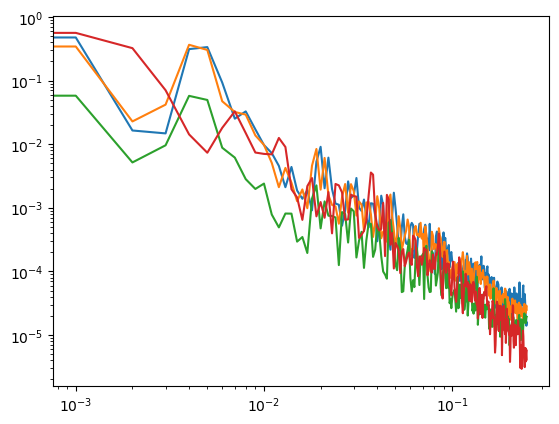

In [4]:
i = 10

plt.loglog(_['left'][i].wavenumber,_['left'][i].expert_psd)
plt.loglog(_['left'][i].wavenumber,_['left'][i].predicted_psd)
plt.loglog(_['left'][i].wavenumber,_['left'][i].aliased_psd)
plt.loglog(_['left'][0].wavenumber,_['left'][0].direct_psd)
#plt.loglog(_['left'][0].wavenumber,_['left'][0].expert_psd)

In [5]:
data_unsmoothed = xr.open_dataset(DATA_DIR+UNSMOOTHED_FILE,group='left'
                                 )
data_unsmoothed

<xarray.Dataset> Size: 4GB
Dimensions:                                (num_lines: 83006, num_pixels: 240,
                                            num_doppler_miti_lines: 10480,
                                            num_doppler_miti_pixels: 24)
Coordinates:
    latitude                               (num_lines, num_pixels) float64 159MB ...
    longitude                              (num_lines, num_pixels) float64 159MB ...
    latitude_doppler_miti                  (num_doppler_miti_lines, num_doppler_miti_pixels) float64 2MB ...
    longitude_doppler_miti                 (num_doppler_miti_lines, num_doppler_miti_pixels) float64 2MB ...
Dimensions without coordinates: num_lines, num_pixels, num_doppler_miti_lines,
                                num_doppler_miti_pixels
Data variables: (12/30)
    time                                   (num_lines) datetime64[ns] 664kB ...
    time_tai                               (num_lines) datetime64[ns] 664kB ...
    latitude_uncert                        (num_lines, num_pixels) float64 159MB ...
    longitude_uncert                       (num_lines, num_pixels) float64 159MB ...
    ssh_karin                              (num_lines, num_pixels) float64 159MB ...
    ssh_karin_qual                         (num_lines, num_pixels) float64 159MB ...
    ...                                     ...
    volumetric_correlation_uncert          (num_lines, num_pixels) float64 159MB ...
    total_coherence                        (num_lines, num_pixels) float64 159MB ...
    time_doppler_miti                      (num_doppler_miti_lines) datetime64[ns] 84kB ...
    time_tai_doppler_miti                  (num_doppler_miti_lines) datetime64[ns] 84kB ...
    geophysical_doppler_miti               (num_doppler_miti_lines, num_doppler_miti_pixels) float64 2MB ...
    surface_velocity_doppler_miti          (num_doppler_miti_lines, num_doppler_miti_pixels) float64 2MB ...
Attributes:
    description:  Unsmoothed SSH measurement data and related information for...

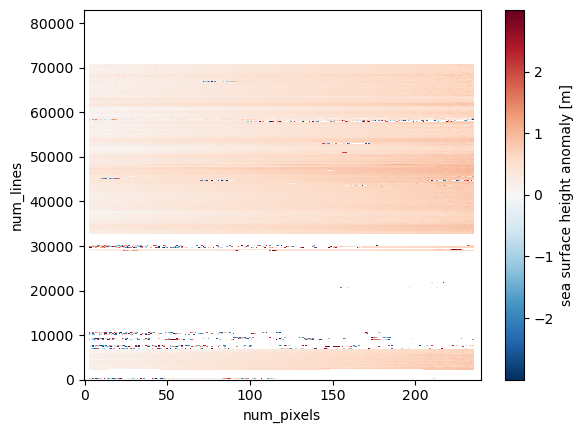

In [6]:
data_unsmoothed['ssha_karin_2'].where((data_unsmoothed['ssha_karin_2_qual']==0)& (np.abs(data_unsmoothed['ssha_karin_2'])<3)).plot()


In [7]:
id_lat = data_unsmoothed['latitude'].where((data_unsmoothed['latitude']<=-50)&(data_unsmoothed['latitude']>=-52),drop=True).num_lines

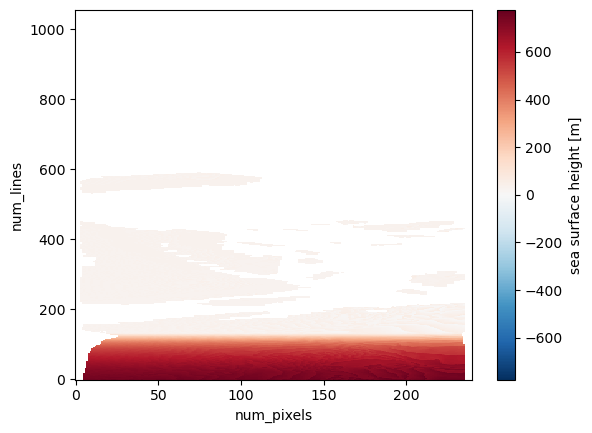

In [8]:
data_unsmoothed['ssh_karin_2'].where(data_unsmoothed['ssh_karin_2_qual']==0).sel(num_lines=id_lat).plot()

In [8]:
import re
SUBDIR = 'SWOT_L2_LR_SSH_Expert_0124'
def parse_year_month(subdir_name, overrides=None):
    """
    Infer (year, month) from a sub-directory name.

    Default rule: the trailing 4 digits are read as MMYY, e.g.
    'SWOT_L2_0225' -> month=2, year=2025.

    For directories that don't follow this convention, pass a dict via
    `overrides` mapping subdir name -> (year, month); it takes precedence
    over the automatic parsing.
    """
    if overrides and subdir_name in overrides:
        return overrides[subdir_name]
    name = subdir_name.rstrip('/').rstrip('\\')
    match = re.search(r'(\d{2})(\d{2})$', name)
    if not match:
        raise ValueError(
            f"Could not infer year/month from subdirectory name '{subdir_name}'. "
            f"Add an explicit entry to DATA_SUBDIR_OVERRIDES instead."
        )
    mm, yy = match.groups()
    month = int(mm)
    year = 2000 + int(yy)
    if not (1 <= month <= 12):
        raise ValueError(f"Parsed invalid month={month} from '{subdir_name}'.")
    return year, month

In [9]:
name = EXPERT_FILE.rstrip('/').rstrip('\\')
re.search(r'(\d{2})(\d{2})$', name)

In [10]:
year, month = parse_year_month(SUBDIR, overrides=None)
#subdir_files = sorted(glob.glob(os.path.join(DATA_DIR, subdir, FILE_PATTERN)))[:]
#    print(f'{subdir:30s} -> {len(subdir_files):4d} files  (year={year}, month={month:02d})')
#    filepaths.extend(subdir_files)
#    file_year_month.extend([(year, month)] * len(subdir_files))

In [11]:

all_segments = []
for swath in ['left','right']:
    for s in _[swath]:
        all_segments.append(s)

In [12]:
def segments_to_dataset(all_segments,year,month):
    expert_psd    = np.stack([s.expert_psd for s in all_segments], axis=0)
    predicted_psd = np.stack([s.predicted_psd for s in all_segments], axis=0)
    aliased_psd   = np.stack([s.aliased_psd for s in all_segments], axis=0)
    direct_psd    = np.stack([s.direct_psd for s in all_segments], axis=0)
    qc_reasons    = np.stack([s.qc_reasons for s in all_segments], axis=0)
    qc_ok    = np.stack([s.qc_ok for s in all_segments], axis=0)
    wavenumber    = all_segments[0].wavenumber
    long_name = 'Along-track SSH(A) PSD (integrated over cross-track)'
    data_vars = dict(
        expert_psd=(['segment', 'wavenumber'], expert_psd,
             {'long_name': long_name, 'units': 'm^2 / (cycles/km)'}),
        predicted_psd=(['segment', 'wavenumber'], predicted_psd,
             {'long_name': long_name, 'units': 'm^2 / (cycles/km)'}),
        aliased_psd=(['segment', 'wavenumber'], aliased_psd,
             {'long_name': long_name, 'units': 'm^2 / (cycles/km)'}),
        direct_psd=(['segment', 'wavenumber'], direct_psd,
             {'long_name': long_name, 'units': 'm^2 / (cycles/km)'}),
        lat_mean=(['segment'], [s.lat_mean for s in all_segments], {'units': 'degrees_north'}),
        lat_min=(['segment'],  [s.lat_min  for s in all_segments], {'units': 'degrees_north'}),
        lat_max=(['segment'],  [s.lat_max  for s in all_segments], {'units': 'degrees_north'}),
        lon_mean=(['segment'], [s.lon_mean for s in all_segments], {'units': 'degrees_east'}),
        qc_reasons=(['segment'], [s.qc_reasons for s in all_segments],),
        qc_ok=(['segment'], [s.qc_ok for s in all_segments],),
#        n_pixels_used=(['segment'], [s.n_pixels_used  for s in all_segments]),
#        valid_fraction=(['segment'], [s.valid_fraction for s in all_segments]),
        swath=(['segment'],   [s.swath    for s in all_segments]),
#        granule=(['segment'], [s._granule for s in all_segments]),
        year=(['segment'], [getattr(s, '_year', year) for s in all_segments],
              {'long_name': 'Year of the source SWOT sub-directory'}),
        month=(['segment'], [getattr(s, '_month', month) for s in all_segments],
               {'long_name': 'Month of the source SWOT sub-directory'}),
    )
    coords = dict(
        wavenumber=('wavenumber', wavenumber, {'units': 'cycles/km'}),
        #wavenumber2d=('wavenumber2D', wavenumber2D_out, {'units': 'cycles/km'}),
        segment=('segment', np.arange(len(all_segments))),
    )
    return xr.Dataset(data_vars=data_vars, coords=coords)
ds = segments_to_dataset(all_segments,year,month)

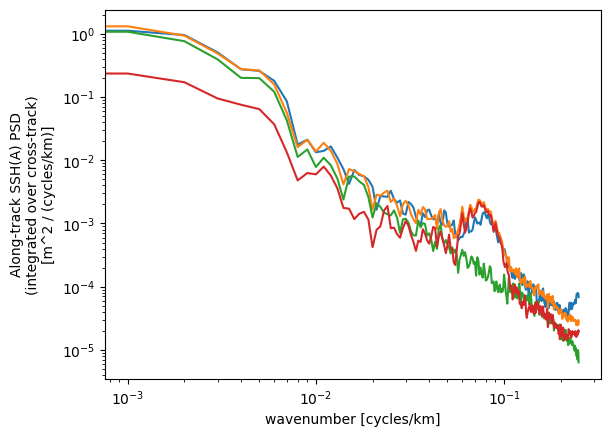

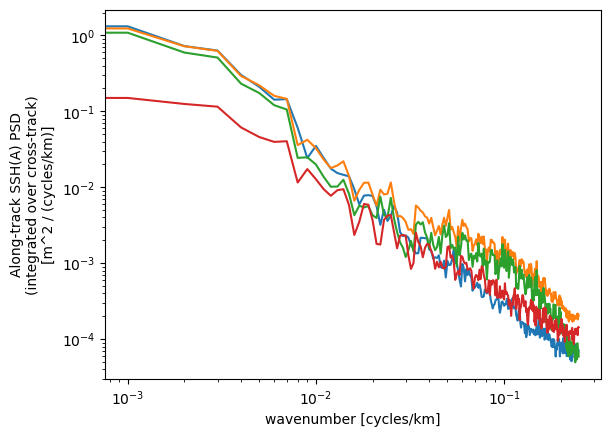

In [13]:
ds.where((ds.swath=='left')&(ds.qc_ok),drop=True).mean('segment').expert_psd.plot(xscale='log',yscale='log')
ds.where((ds.swath=='left')&(ds.qc_ok),drop=True).mean('segment').predicted_psd.plot(xscale='log',yscale='log')
ds.where((ds.swath=='left')&(ds.qc_ok),drop=True).mean('segment').direct_psd.plot(xscale='log',yscale='log')
ds.where((ds.swath=='left')&(ds.qc_ok),drop=True).mean('segment').aliased_psd.plot(xscale='log',yscale='log')


plt.figure()
ds.where((ds.swath=='right')&(ds.qc_ok),drop=True).mean('segment').expert_psd.plot(xscale='log',yscale='log')
ds.where((ds.swath=='right')&(ds.qc_ok),drop=True).mean('segment').predicted_psd.plot(xscale='log',yscale='log')
ds.where((ds.swath=='right')&(ds.qc_ok),drop=True).mean('segment').direct_psd.plot(xscale='log',yscale='log')
ds.where((ds.swath=='right')&(ds.qc_ok),drop=True).mean('segment').aliased_psd.plot(xscale='log',yscale='log')

In [14]:
ds.where(ds.qc_ok==False,drop=True)

<xarray.Dataset> Size: 123kB
Dimensions:        (segment: 15, wavenumber: 250)
Coordinates:
  * segment        (segment) int64 120B 3 4 5 7 8 9 11 15 16 20 21 25 26 31 32
  * wavenumber     (wavenumber) float64 2kB 0.0 0.001 0.002 ... 0.248 0.249
Data variables: (12/13)
    expert_psd     (segment, wavenumber) float64 30kB 0.03005 ... 0.0001236
    predicted_psd  (segment, wavenumber) float64 30kB 0.09128 0.2131 ... 0.05108
    aliased_psd    (segment, wavenumber) float64 30kB 0.02895 ... 0.03221
    direct_psd     (segment, wavenumber) float64 30kB 0.06232 0.1468 ... 0.01887
    lat_mean       (segment) float64 120B -0.694 -4.916 -9.138 ... -47.08 -51.21
    lat_min        (segment) float64 120B -4.946 -9.17 -13.39 ... -51.28 -55.38
    ...             ...
    lon_mean       (segment) float64 120B 60.37 60.99 61.62 ... 69.69 71.53
    qc_reasons     (segment) object 120B 'hf_ratio_high' ... 'hf_ratio_high'
    qc_ok          (segment) float64 120B 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    swath          (segment) object 120B 'left' 'left' ... 'right' 'right'
    year           (segment) float64 120B 2.024e+03 2.024e+03 ... 2.024e+03
    month          (segment) float64 120B 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0

In [15]:
ds_flagged = ds.where(ds.qc_ok,drop=True)

{'whiskers': [<matplotlib.lines.Line2D at 0x17d434050>,
 'caps': [<matplotlib.lines.Line2D at 0x17d4342f0>,
 'boxes': [<matplotlib.lines.Line2D at 0x16cb7be00>,
 'medians': [<matplotlib.lines.Line2D at 0x17d434590>,
 'fliers': [],
 'means': []}

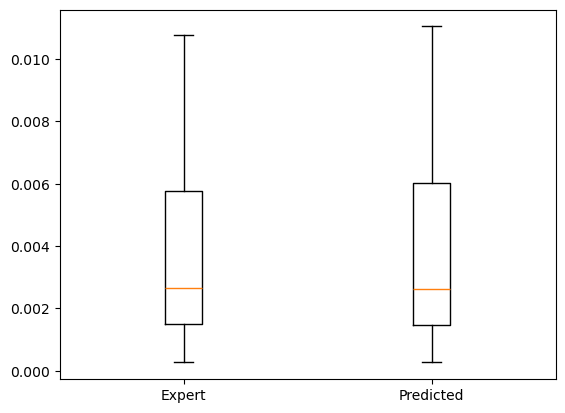

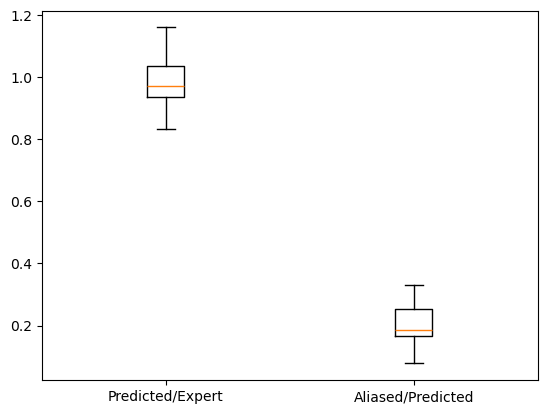

In [16]:
fig,ax = plt.subplots()
ax.boxplot([ds_flagged.expert_psd.integrate('wavenumber'),ds_flagged.predicted_psd.integrate('wavenumber')],tick_labels=['Expert','Predicted'])

fig,ax = plt.subplots()
ax.boxplot([ds_flagged.predicted_psd.integrate('wavenumber')/ds_flagged.expert_psd.integrate('wavenumber'),ds_flagged.aliased_psd.integrate('wavenumber')/ds_flagged.predicted_psd.integrate('wavenumber')],
           tick_labels=['Predicted/Expert','Aliased/Predicted'],showfliers=False)

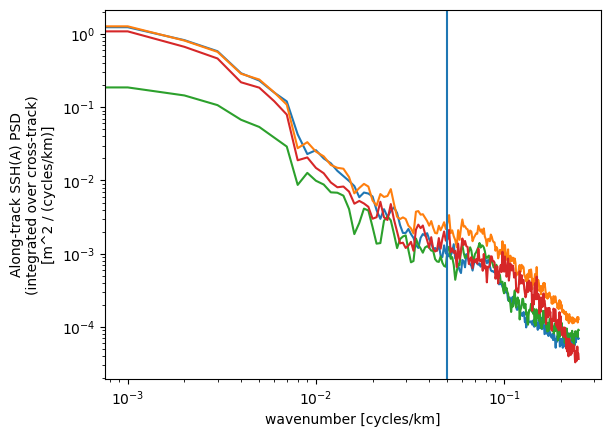

In [17]:
fig,ax = plt.subplots()
ds_flagged.expert_psd.mean('segment').plot(ax=ax,xscale='log',yscale='log')
ds_flagged.predicted_psd.mean('segment').plot(ax=ax,xscale='log',yscale='log')
ds_flagged.aliased_psd.mean('segment').plot(ax=ax,xscale='log',yscale='log')
ds_flagged.direct_psd.mean('segment').plot(ax=ax,xscale='log',yscale='log')
ax.axvline(1/20)

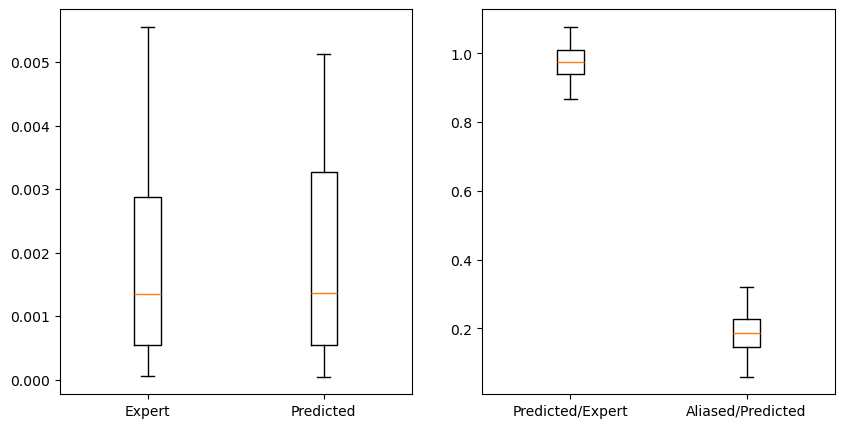

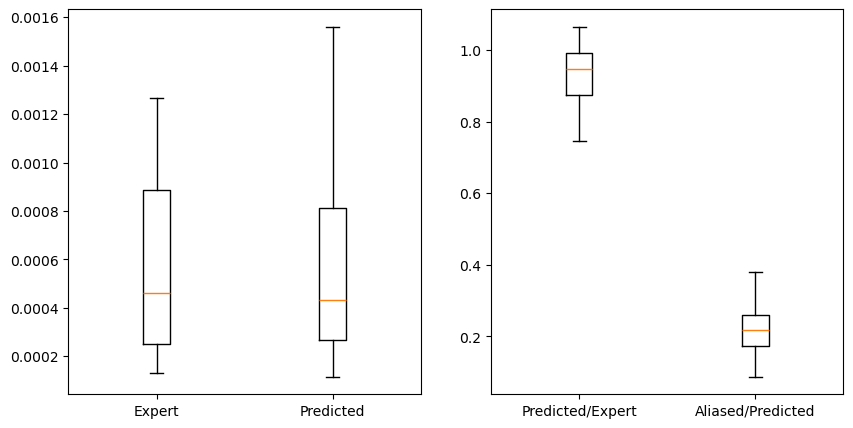

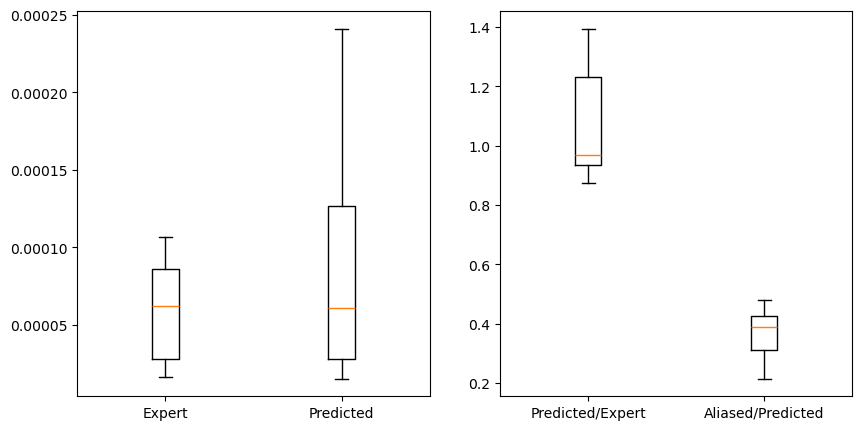

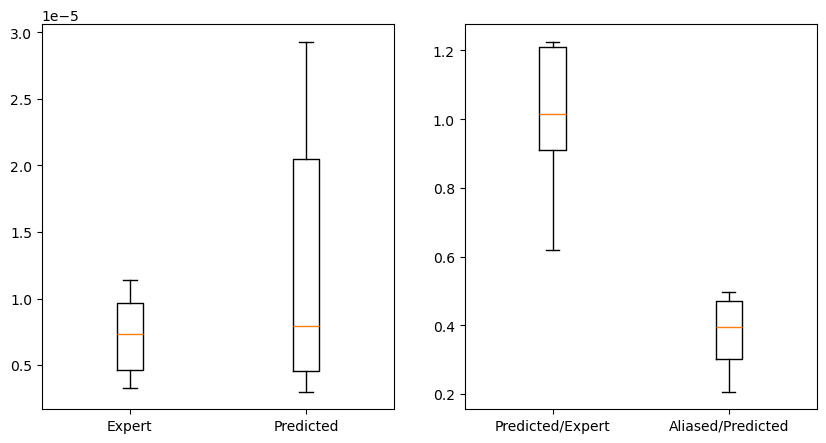

In [18]:
KMIN,KMAX = [1/1000,1/250,1/50,1/10], [1/250,1/50,1/10,1/6]
for kmin,kmax in zip(KMIN,KMAX):
    fig,axs = plt.subplots(1,2,figsize=(10,5))
    ex_psd = ds_flagged.expert_psd.sel(wavenumber=slice(kmin,kmax)).integrate('wavenumber')
    pred_psd = ds_flagged.predicted_psd.sel(wavenumber=slice(kmin,kmax)).integrate('wavenumber')
    alias_psd = ds_flagged.aliased_psd.sel(wavenumber=slice(kmin,kmax)).integrate('wavenumber')
    axs[0].boxplot([ex_psd,pred_psd],tick_labels=['Expert','Predicted'],showfliers=False)
    axs[1].boxplot([pred_psd/ex_psd,alias_psd/pred_psd],tick_labels=['Predicted/Expert','Aliased/Predicted'],showfliers=False)

{'whiskers': [<matplotlib.lines.Line2D at 0x17fea8c20>,
 'caps': [<matplotlib.lines.Line2D at 0x17fea8ec0>,
 'boxes': [<matplotlib.lines.Line2D at 0x17fea8ad0>,
 'medians': [<matplotlib.lines.Line2D at 0x17fea9160>,
 'fliers': [],
 'means': []}

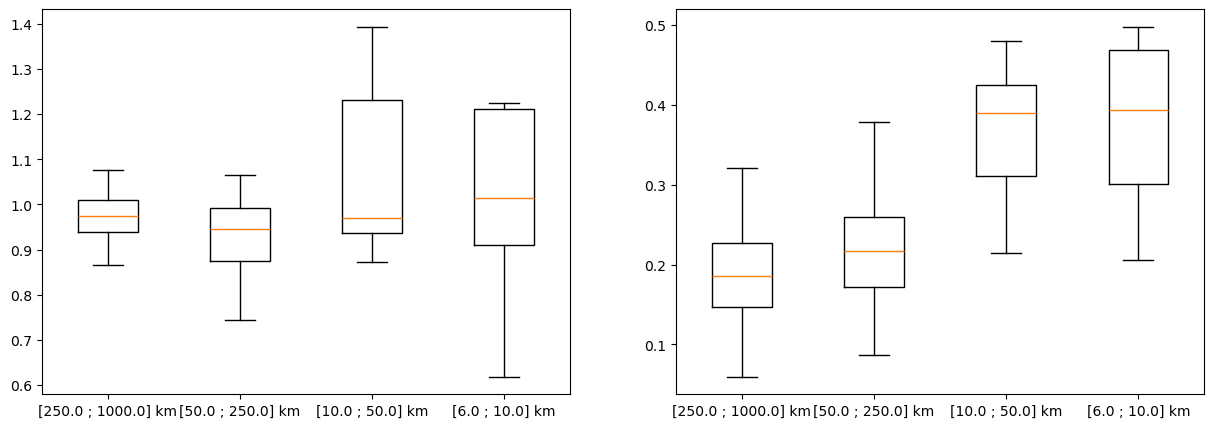

In [19]:
KMIN,KMAX = [1/1000,1/250,1/50,1/10], [1/250,1/50,1/10,1/6]
data_ex_pred = []
data_alias_pred = []
labels = []
fig,axs = plt.subplots(1,2,figsize=(15,5))
for kmin,kmax in zip(KMIN,KMAX):
    ex_psd = ds_flagged.expert_psd.sel(wavenumber=slice(kmin,kmax)).integrate('wavenumber')
    pred_psd = ds_flagged.predicted_psd.sel(wavenumber=slice(kmin,kmax)).integrate('wavenumber')
    alias_psd = ds_flagged.aliased_psd.sel(wavenumber=slice(kmin,kmax)).integrate('wavenumber')
    data_ex_pred.append(pred_psd/ex_psd)
    data_alias_pred.append(alias_psd/pred_psd)
    labels.append(f'[{1/kmax:.1f} ; {1/kmin:.1f}] km')
    
axs[0].boxplot(data_ex_pred,tick_labels=labels,showfliers=False)
axs[1].boxplot(data_alias_pred,tick_labels=labels,showfliers=False)

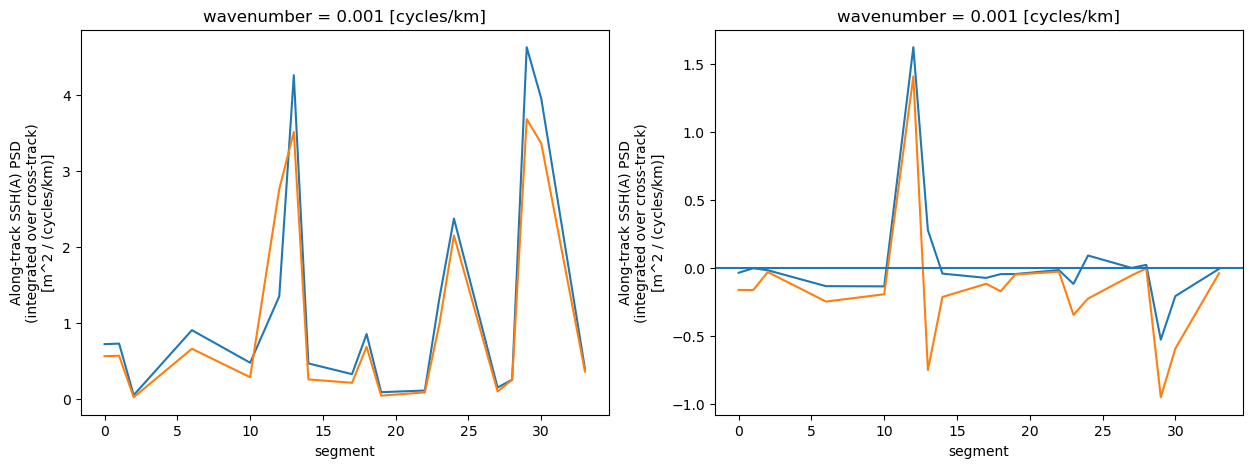

In [20]:
fig,axs = plt.subplots(1,2,figsize=(15,5))
ds_flagged.isel(wavenumber=1).expert_psd.plot(ax=axs[0])
ds_flagged.isel(wavenumber=1).direct_psd.plot(ax=axs[0])
(ds_flagged.isel(wavenumber=1).direct_psd+ds_flagged.isel(wavenumber=1).aliased_psd-ds_flagged.isel(wavenumber=1).expert_psd).plot(ax=axs[1])
(ds_flagged.isel(wavenumber=1).direct_psd-ds_flagged.isel(wavenumber=1).expert_psd).plot(ax=axs[1])
axs[1].axhline(0)

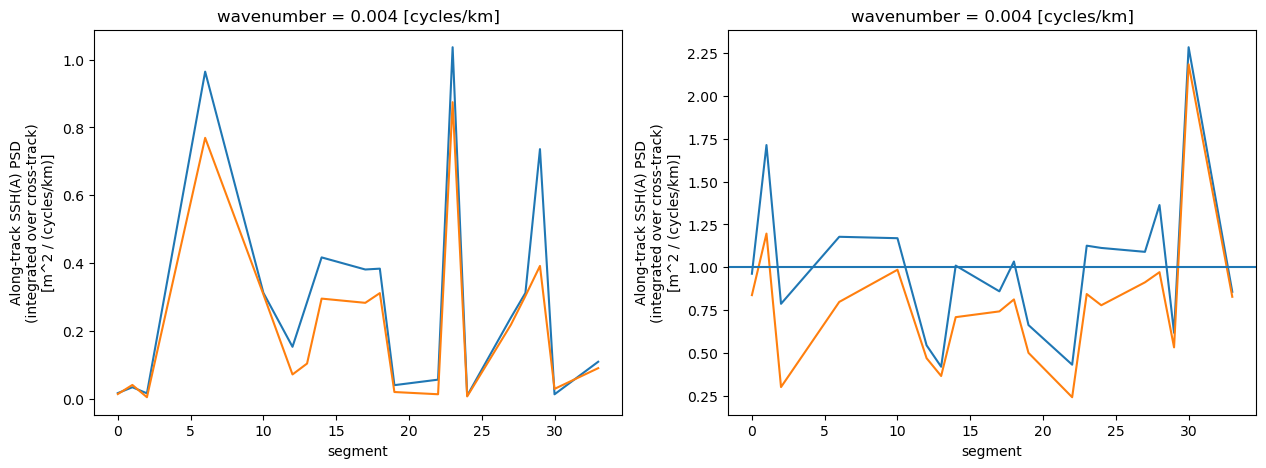

In [22]:
fig,axs = plt.subplots(1,2,figsize=(15,5))
ds_flagged.sel(wavenumber=1/250,method='nearest').expert_psd.plot(ax=axs[0])
ds_flagged.sel(wavenumber=1/250,method='nearest').direct_psd.plot(ax=axs[0])
((ds_flagged.sel(wavenumber=1/250,method='nearest').direct_psd+ds_flagged.sel(wavenumber=1/250,method='nearest').aliased_psd)/ds_flagged.sel(wavenumber=1/250,method='nearest').expert_psd).plot(ax=axs[1])
(ds_flagged.sel(wavenumber=1/250,method='nearest').direct_psd/ds_flagged.sel(wavenumber=1/250,method='nearest').expert_psd).plot(ax=axs[1])
axs[1].axhline(1)

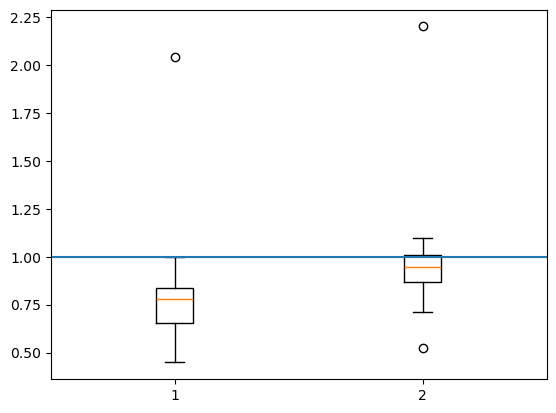

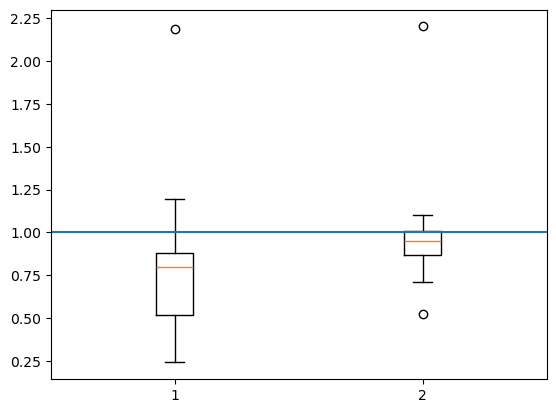

In [23]:
fig,ax = plt.subplots()
ax.boxplot([ds_flagged.sel(wavenumber=1/1000,method='nearest').direct_psd/ds_flagged.sel(wavenumber=1/1000,method='nearest').expert_psd,(ds_flagged.sel(wavenumber=1/1000,method='nearest').direct_psd+ds_flagged.sel(wavenumber=1/1000,method='nearest').aliased_psd)/ds_flagged.sel(wavenumber=1/1000,method='nearest').expert_psd])
ax.axhline(1.)
fig,ax = plt.subplots()
ax.boxplot([ds_flagged.sel(wavenumber=1/250,method='nearest').direct_psd/ds_flagged.sel(wavenumber=1/250,method='nearest').expert_psd,(ds_flagged.sel(wavenumber=1/1000,method='nearest').direct_psd+ds_flagged.sel(wavenumber=1/1000,method='nearest').aliased_psd)/ds_flagged.sel(wavenumber=1/1000,method='nearest').expert_psd])
ax.axhline(1.)